# Visualize heatmap models

Pick any architecture from `ARCH_REGISTRY` (RGB CNN, frame-diff CNN, event-frame CNN, …).
Loads the matching val batch + checkpoint, shows a modality-aware preview + GT / pred heatmaps + overlay.

Set `USE_CROP = True` to sample jittered bucket crops (same as `--crop` training): each row shows the **crop**, whether the ball is **in_crop**, GT / pred heatmaps, and predicted **σ** when the checkpoint has a `log_σ` head.

New models work automatically once registered in `horus.eval.bench.ARCH_REGISTRY` with a `checkpoints/<arch>.pt` file.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from horus.config import load_config, repo_root
from horus.data.dataset import build_dataloader
from horus.eval import ARCH_REGISTRY, load_model
from horus.eval.metrics import input_channels
from horus.models import heatmap_to_coords, unpack_model_output

# =============================================================================
# Controls — edit, then re-run this cell and below
# =============================================================================
ARCH = "rgb_cnn"  # rgb_cnn | diff_cnn | event_frame_cnn | event_frame_snn | …
SPLIT = "val"
BATCH_SIZE = 4
USE_CROP = True  # True → jittered bucket crops (+ negatives); False → full frame
SEED = 0  # crop RNG; None = nondeterministic
# Optional override; None → checkpoints/<ARCH>.pt
CKPT_NAME = None  # e.g. "rgb_cnn.pt"
# =============================================================================

ROOT = repo_root()
cfg = load_config()
if USE_CROP:
    cfg.setdefault("crop", {})["enabled"] = True
else:
    cfg.setdefault("crop", {})["enabled"] = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if ARCH not in ARCH_REGISTRY:
    raise KeyError(f"Unknown ARCH={ARCH!r}. Known: {sorted(ARCH_REGISTRY)}")
_, modality = ARCH_REGISTRY[ARCH]
ckpt_path = ROOT / "checkpoints" / (CKPT_NAME or f"{ARCH}.pt")
if not ckpt_path.is_file():
    raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}")

model = load_model(ARCH, ckpt_path, device)
ckpt_meta = torch.load(ckpt_path, map_location="cpu", weights_only=True)
has_sigma = bool(
    ckpt_meta.get("predict_uncertainty", ckpt_meta.get("crop", False))
)
print(
    f"arch={ARCH} modality={modality} in_ch={input_channels(modality, cfg)} "
    f"crop={USE_CROP} sigma_head={has_sigma} "
    f"epoch={ckpt_meta.get('epoch')} val_px={ckpt_meta.get('val_px')} device={device}"
)
print(f"ckpt={ckpt_path.name}  registered: {sorted(ARCH_REGISTRY)}")

loader = build_dataloader(
    cfg,
    SPLIT,
    modality,
    batch_size=BATCH_SIZE,
    num_workers=0,
    shuffle=False,
    seed=SEED,
)
batch = next(iter(loader))
with torch.no_grad():
    out = model(batch["input"].to(device))
pred, log_sigma = unpack_model_output(out)
pred = pred.cpu()
log_sigma = None if log_sigma is None else log_sigma.cpu()
gt, coords = batch["heatmap"], batch["coords"]
pred_xy = heatmap_to_coords(pred)
in_crop = batch.get("in_crop", batch["visible"])
crop_origin = batch.get("crop_origin")
crop_size = batch.get("crop_size")

arch=rgb_cnn modality=rgb in_ch=9 crop=True sigma_head=True epoch=3 val_px=55.615993540066896 device=cuda
ckpt=rgb_cnn.pt  registered: ['diff_cnn', 'event_frame_cnn', 'event_frame_snn', 'rgb_cnn']


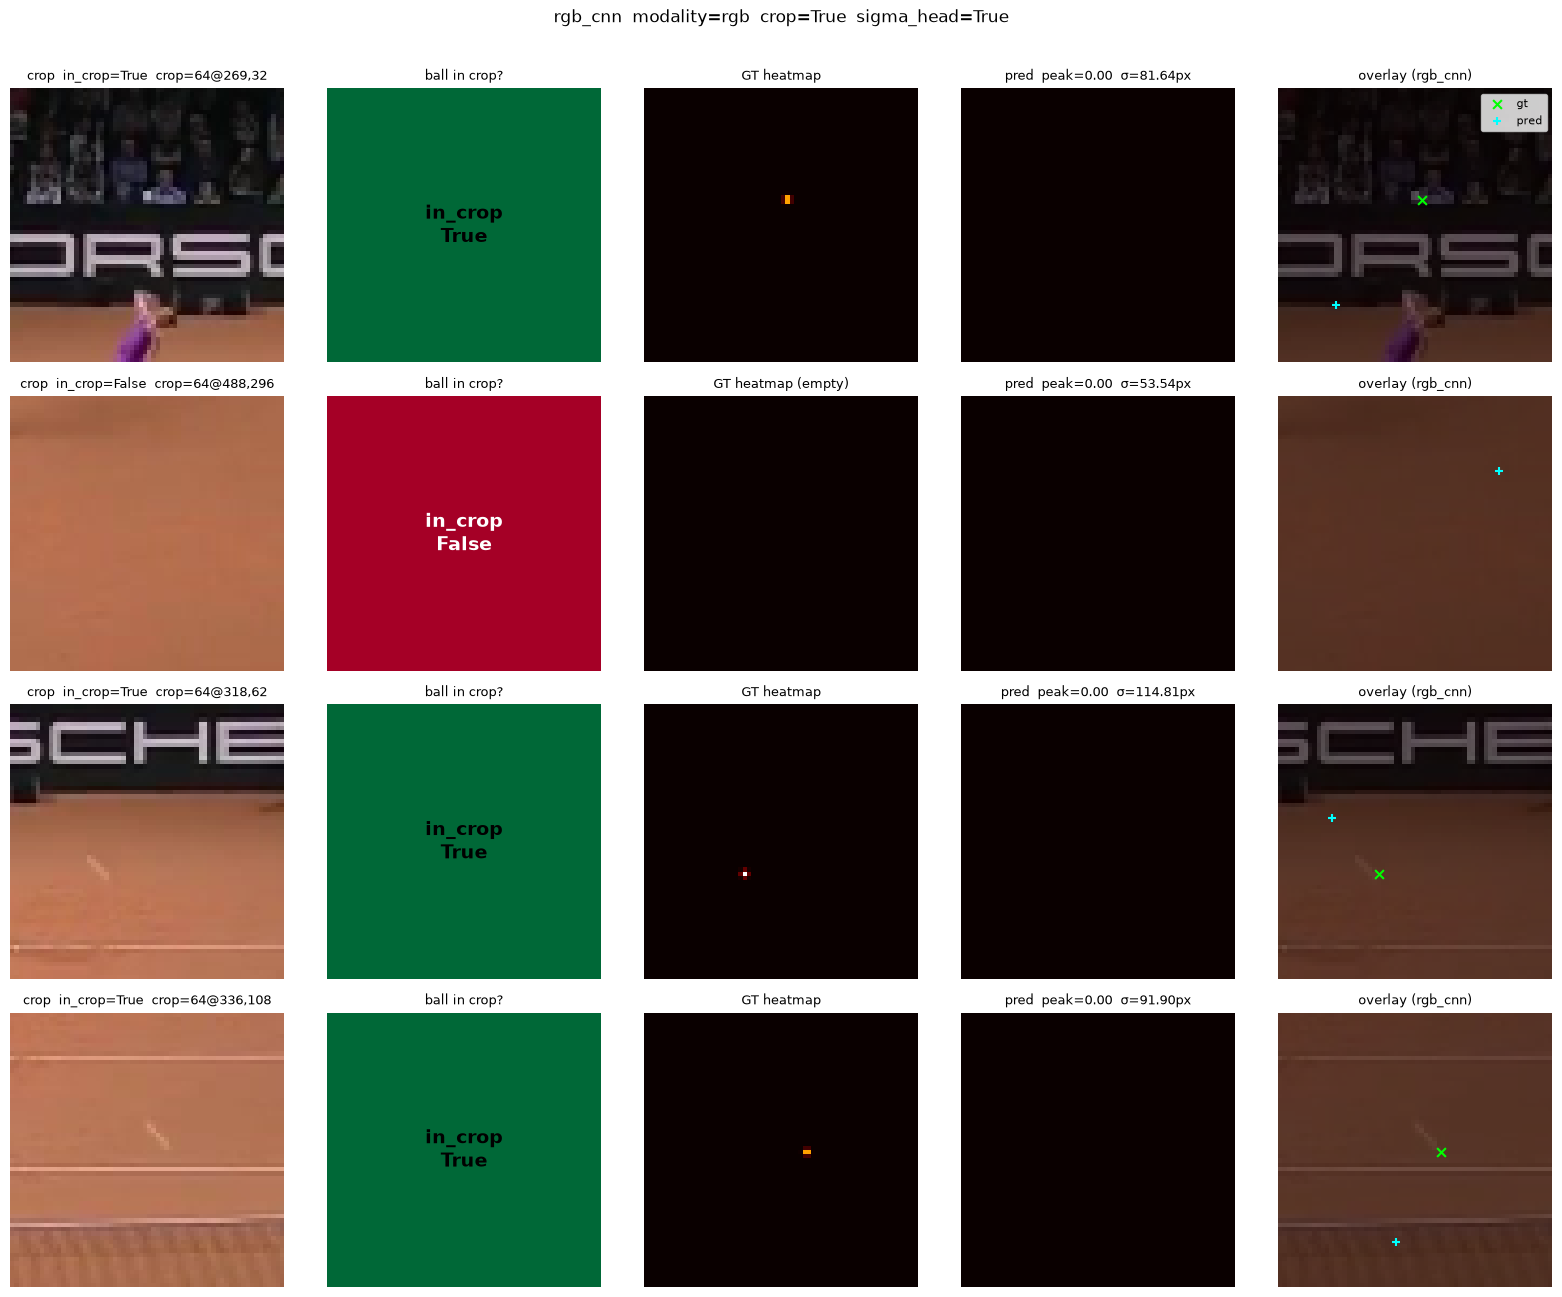

 i  game/clip           frame         in_crop    peak        σ           gt_xy         pred_xy
 0  game8/Clip1         0002.jpg         True   0.003    81.64         (33,26)  (13,50)
 1  game8/Clip1         0005.jpg        False   0.003    53.54               —  (51,17)
 2  game8/Clip1         0008.jpg         True   0.003   114.81         (23,39)  (12,26)
 3  game8/Clip1         0011.jpg         True   0.003    91.90         (38,32)  (27,53)


In [2]:
def preview_input(chw: torch.Tensor, modality: str, cfg: dict) -> np.ndarray:
    """Turn a stacked model input (C, H, W) into an HxWx3 float image for imshow.

    Uses the *last* frame / window slice so GT labels align with the preview.
    Works for both full-frame and square crop tensors.
    """
    x = chw.detach().float().cpu().numpy()
    _, h, w = x.shape

    if modality == "rgb":
        # (3N, H, W) → last RGB frame
        frame = x[-3:].transpose(1, 2, 0)
        return np.clip(frame, 0, 1)

    if modality == "diff":
        # (N-1, H, W) → last abs-diff as gray
        g = x[-1]
        g = g / (g.max() + 1e-8)
        return np.stack([g, g, g], axis=-1)

    if modality == "event_frame":
        # (2N, H, W) polarity pairs → last frame as R=pos, B=neg
        pos, neg = x[-2], x[-1]
        scale = max(float(pos.max()), float(neg.max()), 1e-8)
        rgb = np.zeros((h, w, 3), dtype=np.float32)
        rgb[..., 0] = pos / scale
        rgb[..., 2] = neg / scale
        return np.clip(rgb, 0, 1)

    if modality == "voxel":
        bins = int(cfg.get("events", {}).get("voxel", {}).get("num_bins", 5))
        last = x[-bins:]  # (bins, H, W)
        g = np.abs(last).sum(axis=0)
        g = g / (g.max() + 1e-8)
        return np.stack([g, g, g], axis=-1)

    # Fallback for unknown future modalities: mean across channels
    g = np.abs(x).mean(axis=0)
    g = g / (g.max() + 1e-8)
    return np.stack([g, g, g], axis=-1)


n = pred.shape[0]
ncols = 5 if USE_CROP else 4
fig, axes = plt.subplots(n, ncols, figsize=(3.2 * ncols, 3.2 * n))
if n == 1:
    axes = np.asarray(axes).reshape(1, -1)

for i in range(n):
    frame = preview_input(batch["input"][i], modality, cfg)
    g, p = gt[i, 0].numpy(), pred[i, 0].numpy()
    gx, gy = coords[i].tolist()
    px, py = pred_xy[i].tolist()
    ball_in = bool(float(in_crop[i].item()) > 0.5)
    peak = float(p.max())

    sigma_str = ""
    if log_sigma is not None:
        sigma = float(torch.exp(log_sigma[i]).item())
        sigma_str = f"  σ={sigma:.2f}px"

    crop_str = ""
    if USE_CROP and crop_origin is not None and crop_size is not None:
        x0, y0 = int(crop_origin[i, 0]), int(crop_origin[i, 1])
        sz = int(crop_size[i].item()) if torch.is_tensor(crop_size[i]) else int(crop_size[i])
        crop_str = f"  crop={sz}@{x0},{y0}"

    # Col 0: input (crop or full frame)
    axes[i, 0].imshow(frame)
    title0 = f"{batch['game'][i]}/{batch['clip'][i]} {batch['frame'][i]}"
    if USE_CROP:
        title0 = f"crop  in_crop={ball_in}{crop_str}"
    axes[i, 0].set_title(title0, fontsize=9)

    if USE_CROP:
        # Col 1: in_crop boolean panel
        axes[i, 1].imshow(
            np.full_like(frame[..., 0], 1.0 if ball_in else 0.0),
            cmap="RdYlGn",
            vmin=0,
            vmax=1,
        )
        axes[i, 1].text(
            0.5,
            0.5,
            f"in_crop\n{ball_in}",
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
            color="black" if ball_in else "white",
            transform=axes[i, 1].transAxes,
        )
        axes[i, 1].set_title("ball in crop?", fontsize=9)
        gt_ax, pred_ax, overlay_ax = axes[i, 2], axes[i, 3], axes[i, 4]
    else:
        gt_ax, pred_ax, overlay_ax = axes[i, 1], axes[i, 2], axes[i, 3]

    gt_ax.imshow(g, cmap="hot", vmin=0, vmax=1)
    gt_ax.set_title("GT heatmap" + (" (empty)" if not ball_in else ""), fontsize=9)

    pred_ax.imshow(p, cmap="hot", vmin=0, vmax=1)
    pred_ax.set_title(f"pred  peak={peak:.2f}{sigma_str}", fontsize=9)

    overlay_ax.imshow(frame)
    overlay_ax.imshow(p, cmap="hot", alpha=0.55, vmin=0, vmax=1)
    if ball_in:
        overlay_ax.scatter([gx], [gy], c="lime", s=40, marker="x", label="gt")
    overlay_ax.scatter([px], [py], c="cyan", s=40, marker="+", label="pred")
    overlay_ax.set_title(f"overlay ({ARCH})", fontsize=9)
    if i == 0:
        overlay_ax.legend(loc="upper right", fontsize=8)

for ax in axes.ravel():
    ax.axis("off")
plt.suptitle(
    f"{ARCH}  modality={modality}  crop={USE_CROP}  sigma_head={has_sigma}",
    y=1.01,
)
plt.tight_layout()
plt.show()

# Per-sample summary table
print(
    f"{'i':>2}  {'game/clip':<18}  {'frame':<12}  {'in_crop':>7}  "
    f"{'peak':>6}  {'σ':>7}  {'gt_xy':>14}  {'pred_xy':>14}"
)
for i in range(n):
    ball_in = bool(float(in_crop[i].item()) > 0.5)
    peak = float(pred[i, 0].max().item())
    sig = float(torch.exp(log_sigma[i]).item()) if log_sigma is not None else float("nan")
    gx, gy = coords[i].tolist()
    px, py = pred_xy[i].tolist()
    gt_s = f"({gx:.0f},{gy:.0f})" if ball_in else "—"
    print(
        f"{i:2d}  {batch['game'][i]}/{batch['clip'][i]:<12}  "
        f"{str(batch['frame'][i]):<12}  "
        f"{str(ball_in):>7}  {peak:6.3f}  {sig:7.2f}  "
        f"{gt_s:>14}  ({px:.0f},{py:.0f})"
    )